# DermaMate AI — Notebook 02: Model Training, Evaluation, TTA & Production Export (5 Skin Classes)
**Autonomous AI/Computer Vision Pipeline (Tahap 4)**
- **5 Kategori Kulit Wajah:** `acne` (jerawat / acne-prone), `combination` (kombinasi), `dry` (kering), `normal` (normal), `oily` (berminyak).
- **Arsitektur Kandidat:** `resnet50` (`IMAGENET1K_V2`) & `efficientnet_b0` (`DEFAULT`)
- **Strategi Pelatihan:** 2-Fase Anti *Catastrophic Forgetting* (Fase 1 Head Warmup 8 Epoch + Fase 2 Gradual Fine-Tuning 20 Epoch dengan `freeze_bn`, Differential Learning Rate, `ReduceLROnPlateau`, dan `EarlyStopping`)
- **Target KPI Project Charter:** Validation & Test Accuracy dan Macro F1-Score **>= 85% (0.85)** serta Latensi Inferensi End-to-End **<= 10 detik**.

In [1]:
# ==============================================================================
# CELL 1: HARDWARE ACCELERATION & REPRODUCIBILITY
# ==============================================================================
import os
import time
import json
import copy
import random
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
from PIL import Image
import mediapipe as mp

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import torchvision
from torchvision import transforms
from torchvision.transforms import functional as TF

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    f1_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns
import onnx
import onnxruntime as ort

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

SEED = 42
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(SEED)
torch.set_flush_denormal(True)
torch.set_num_threads(min(12, os.cpu_count() or 4))

if torch.cuda.is_available():
    device = torch.device('cuda')
elif hasattr(torch.backends, 'mps') and torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

USE_AMP = (device.type == 'cuda')
scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SPLIT_MANIFEST_PATH = PROJECT_ROOT / 'dataset_kulit' / 'split_manifest.csv'
CKPT_DIR = PROJECT_ROOT / 'models' / 'checkpoints'
EVAL_DIR = PROJECT_ROOT / 'models' / 'evaluation'
CKPT_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR.mkdir(parents=True, exist_ok=True)

print(f'Selected Device : {device} (AMP Enabled: {USE_AMP})')
print(f'PyTorch Version : {torch.__version__}')
print(f'CPU Threads     : {torch.get_num_threads()}')
print(f'Split Manifest  : {SPLIT_MANIFEST_PATH}')

Selected Device : cpu (AMP Enabled: False)
PyTorch Version : 2.15.0+cpu
CPU Threads     : 12
Split Manifest  : D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\dataset_kulit\split_manifest.csv


In [2]:
# ==============================================================================
# CELL 2: DERMATOLOGY-SAFE AUGMENTATION & PYTORCH DATALOADER
# ==============================================================================
split_df = pd.read_csv(SPLIT_MANIFEST_PATH)
assert (split_df['skipped'] == 0).all(), 'Seluruh sampel pada split_manifest harus memiliki skipped == 0!'

CLASSES = sorted(split_df['label'].unique().tolist())
CLASS_TO_IDX = {cls_name: idx for idx, cls_name in enumerate(CLASSES)}
IDX_TO_CLASS = {idx: cls_name for cls_name, idx in CLASS_TO_IDX.items()}
NUM_CLASSES = len(CLASSES)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Transformasi Train: Dermatology-Safe (Tanpa GaussianBlur yang merusak tekstur pori/sebum)
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.RandomResizedCrop(size=224, scale=(0.85, 1.0)),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Transformasi Val/Test: Resize((224, 224)) + Normalize standar ImageNet
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

class DermaMateSkinDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform=None):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.labels = [CLASS_TO_IDX[lbl] for lbl in self.df['label']]
        self.filepaths = [PROJECT_ROOT / fp for fp in self.df['filepath']]
        # Cache PIL images in RAM (total ~65MB) untuk menghilangkan bottleneck disk I/O
        self.images = [Image.open(p).convert('RGB') for p in self.filepaths]

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img = self.images[idx]
        label = self.labels[idx]
        if self.transform is not None:
            img_tensor = self.transform(img)
        else:
            img_tensor = transforms.ToTensor()(img)
        return img_tensor, label

train_df = split_df[split_df['split'] == 'train'].reset_index(drop=True)
val_df = split_df[split_df['split'] == 'val'].reset_index(drop=True)
test_df = split_df[split_df['split'] == 'test'].reset_index(drop=True)

train_dataset = DermaMateSkinDataset(train_df, transform=train_transform)
val_dataset = DermaMateSkinDataset(val_df, transform=eval_transform)
test_dataset = DermaMateSkinDataset(test_df, transform=eval_transform)

# WeightedRandomSampler pada train_loader agar setiap batch seimbang sempurna antar kelas
train_targets = np.array(train_dataset.labels)
class_sample_counts = np.bincount(train_targets, minlength=NUM_CLASSES)
class_weights = 1.0 / np.sqrt(np.maximum(class_sample_counts, 1))
sample_weights = torch.DoubleTensor(class_weights[train_targets])

sampler_generator = torch.Generator().manual_seed(SEED)
train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True,
    generator=sampler_generator
)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=train_sampler, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f'Kelas ({NUM_CLASSES})     : {CLASSES} -> {CLASS_TO_IDX}')
print(f'Train Samples : {len(train_dataset)} (Class counts: {dict(zip(CLASSES, class_sample_counts))})')
print(f'Val Samples   : {len(val_dataset)}')
print(f'Test Samples  : {len(test_dataset)}')
xb, yb = next(iter(train_loader))
print(f'Sample Batch  : shape={xb.shape}, Balanced batch counts={dict(zip(CLASSES, np.bincount(yb.numpy(), minlength=NUM_CLASSES)))}')

Kelas (5)     : ['acne', 'combination', 'dry', 'normal', 'oily'] -> {'acne': 0, 'combination': 1, 'dry': 2, 'normal': 3, 'oily': 4}
Train Samples : 368 (Class counts: {'acne': np.int64(126), 'combination': np.int64(21), 'dry': np.int64(69), 'normal': np.int64(85), 'oily': np.int64(67)})
Val Samples   : 46
Test Samples  : 47
Sample Batch  : shape=torch.Size([32, 3, 224, 224]), Balanced batch counts={'acne': np.int64(5), 'combination': np.int64(3), 'dry': np.int64(13), 'normal': np.int64(7), 'oily': np.int64(4)}


In [3]:
# ==============================================================================
# CELL 3: KANDIDAT ARSITEKTUR SESUAI PROJECT CHARTER (resnet50 & efficientnet_b0)
# ==============================================================================
def build_classifier_head(in_features: int, num_classes: int) -> nn.Sequential:
    """Classifier head teregulasi kuat sesuai spesifikasi Project Charter."""
    return nn.Sequential(
        nn.BatchNorm1d(in_features),
        nn.Dropout(p=0.4),
        nn.Linear(in_features, 256),
        nn.GELU(),
        nn.Dropout(p=0.2),
        nn.Linear(256, num_classes)
    )

def create_dermamate_model(arch_name: str, num_classes: int = NUM_CLASSES) -> nn.Module:
    arch_name = arch_name.lower().strip()
    if arch_name == 'resnet50':
        model = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
        in_features = model.fc.in_features
        model.fc = build_classifier_head(in_features, num_classes)
    elif arch_name == 'efficientnet_b0':
        model = torchvision.models.efficientnet_b0(weights=torchvision.models.EfficientNet_B0_Weights.DEFAULT)
        in_features = model.classifier[1].in_features
        model.classifier = build_classifier_head(in_features, num_classes)
    else:
        raise ValueError(f'Arsitektur tidak didukung: {arch_name}')
    return model.to(device)

def get_head_and_phase2_modules(model: nn.Module, arch_name: str):
    arch_name = arch_name.lower().strip()
    if arch_name == 'resnet50':
        head_module = model.fc
        phase2_backbone_modules = [model.layer3, model.layer4]
    elif arch_name == 'efficientnet_b0':
        head_module = model.classifier
        phase2_backbone_modules = [model.features[-4:]]
    else:
        raise ValueError(f'Arsitektur tidak didukung: {arch_name}')
    return head_module, phase2_backbone_modules

for test_arch in ['resnet50', 'efficientnet_b0']:
    m_tmp = create_dermamate_model(test_arch, NUM_CLASSES)
    total_p = sum(p.numel() for p in m_tmp.parameters())
    head_m, _ = get_head_and_phase2_modules(m_tmp, test_arch)
    head_p = sum(p.numel() for p in head_m.parameters())
    print(f'[{test_arch}] Total Params: {total_p:,} | Regulated Head Params: {head_p:,}')
    print(head_m)
    del m_tmp

[resnet50] Total Params: 24,037,957 | Regulated Head Params: 529,925
Sequential(
  (0): BatchNorm1d(2048, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (1): Dropout(p=0.4, inplace=False)
  (2): Linear(in_features=2048, out_features=256, bias=True)
  (3): GELU(approximate='none')
  (4): Dropout(p=0.2, inplace=False)
  (5): Linear(in_features=256, out_features=5, bias=True)
)


[efficientnet_b0] Total Params: 4,339,329 | Regulated Head Params: 331,781
Sequential(
  (0): BatchNorm1d(1280, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (1): Dropout(p=0.4, inplace=False)
  (2): Linear(in_features=1280, out_features=256, bias=True)
  (3): GELU(approximate='none')
  (4): Dropout(p=0.2, inplace=False)
  (5): Linear(in_features=256, out_features=5, bias=True)
)


In [4]:
# ==============================================================================
# CELL 4: STRATEGI PELATIHAN 2-FASE ANTI CATASTROPHIC FORGETTING
# ==============================================================================
def freeze_bn(model: nn.Module):
    """Mengunci seluruh layer nn.BatchNorm2d ke mode .eval() dan requires_grad=False."""
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()
            for param in module.parameters():
                param.requires_grad = False

class EarlyStopping:
    def __init__(self, patience: int = 6, min_delta: float = 1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.best_score = -np.inf
        self.counter = 0
        self.early_stop = False

    def step(self, score: float) -> bool:
        if score > self.best_score + self.min_delta:
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop

@torch.no_grad()
def evaluate_epoch(model: nn.Module, loader: DataLoader, criterion: nn.Module):
    model.eval()
    total_loss = 0.0
    all_preds, all_targets = [], []
    for images, targets in loader:
        images = images.to(device)
        targets = targets.to(device)
        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, targets)
        total_loss += loss.item() * images.size(0)
        preds = logits.argmax(dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())
    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average='macro')
    return avg_loss, acc, macro_f1

def train_two_phase_model(arch_name: str, phase1_epochs: int = 8, phase2_epochs: int = 20):
    print(f'\n' + '=' * 78)
    print(f'MULAI PELATIHAN 2-FASE: {arch_name.upper()}')
    print('=' * 78)
    seed_everything(SEED)
    model = create_dermamate_model(arch_name, NUM_CLASSES)
    head_module, phase2_backbone_modules = get_head_and_phase2_modules(model, arch_name)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    history = {
        'epoch': [], 'phase': [],
        'train_loss': [], 'val_loss': [],
        'train_acc': [], 'val_acc': [],
        'train_f1': [], 'val_f1': []
    }

    best_val_f1 = -1.0
    best_model_state = copy.deepcopy(model.state_dict())

    # --------------------------------------------------------------------------
    # FASE 1: HEAD WARMUP (8 EPOCH) - Freeze seluruh backbone
    # --------------------------------------------------------------------------
    for param in model.parameters():
        param.requires_grad = False
    for param in head_module.parameters():
        param.requires_grad = True
    freeze_bn(model)

    optimizer_p1 = torch.optim.AdamW(
        [p for p in head_module.parameters() if p.requires_grad],
        lr=1e-3, weight_decay=1e-2
    )
    scheduler_p1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_p1, T_max=phase1_epochs, eta_min=1e-5)

    print(f'\n--- [FASE 1: Head Warmup ({phase1_epochs} Epoch)] ---')
    for ep in range(1, phase1_epochs + 1):
        t_ep = time.time()
        model.train()
        freeze_bn(model)
        running_loss = 0.0
        tr_preds, tr_targets = [], []

        for images, targets in train_loader:
            images, targets = images.to(device), targets.to(device)
            optimizer_p1.zero_grad()
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(images)
                loss = criterion(logits, targets)
            if USE_AMP:
                scaler.scale(loss).backward()
                scaler.step(optimizer_p1)
                scaler.update()
            else:
                loss.backward()
                optimizer_p1.step()

            running_loss += loss.item() * images.size(0)
            tr_preds.extend(logits.argmax(dim=1).detach().cpu().numpy())
            tr_targets.extend(targets.cpu().numpy())

        scheduler_p1.step()
        tr_loss = running_loss / len(train_loader.dataset)
        tr_acc = accuracy_score(tr_targets, tr_preds)
        tr_f1 = f1_score(tr_targets, tr_preds, average='macro')
        val_loss, val_acc, val_f1 = evaluate_epoch(model, val_loader, criterion)

        marker = ''
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_model_state = copy.deepcopy(model.state_dict())
            marker = ' * [BEST P1]'

        history['epoch'].append(ep)
        history['phase'].append('Phase 1 (Warmup)')
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(val_acc)
        history['train_f1'].append(tr_f1)
        history['val_f1'].append(val_f1)

        print(
            f'P1 Epoch {ep:02d}/{phase1_epochs:02d} ({time.time()-t_ep:.1f}s) | '
            f'Train Loss: {tr_loss:.4f} F1: {tr_f1:.4f} | '
            f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} Macro-F1: {val_f1:.4f}{marker}'
        )

    # --------------------------------------------------------------------------
    # FASE 2: GRADUAL FINE-TUNING + FROZEN BATCHNORM (20 EPOCH)
    # Wajib: Muat kembali best_model_state dari akhir Fase 1
    # --------------------------------------------------------------------------
    print(f'\n[Transisi Fase 1 -> Fase 2] Memuat ulang best_model_state Fase 1 (Val Macro-F1: {best_val_f1:.4f})')
    model.load_state_dict(best_model_state)

    for param in model.parameters():
        param.requires_grad = False
    for blk in phase2_backbone_modules:
        for param in blk.parameters():
            param.requires_grad = True
    for param in head_module.parameters():
        param.requires_grad = True

    # Wajib: Kunci seluruh layer nn.BatchNorm2d ke .eval() dan requires_grad=False
    freeze_bn(model)

    backbone_params = []
    for blk in phase2_backbone_modules:
        backbone_params.extend([p for p in blk.parameters() if p.requires_grad])
    head_params = [p for p in head_module.parameters() if p.requires_grad]

    optimizer_p2 = torch.optim.AdamW([
        {'params': backbone_params, 'lr': 3e-5, 'weight_decay': 1e-2},
        {'params': head_params, 'lr': 1.5e-4, 'weight_decay': 1e-2},
    ])
    scheduler_p2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer_p2, mode='max', factor=0.5, patience=2
    )
    early_stopper = EarlyStopping(patience=6)
    early_stopper.step(best_val_f1)

    print(f'--- [FASE 2: Gradual Fine-Tuning ({phase2_epochs} Epoch, Frozen BN, Diff LR)] ---')
    for ep in range(1, phase2_epochs + 1):
        t_ep = time.time()
        model.train()
        freeze_bn(model)
        running_loss = 0.0
        tr_preds, tr_targets = [], []

        for images, targets in train_loader:
            images, targets = images.to(device), targets.to(device)
            optimizer_p2.zero_grad()
            with torch.cuda.amp.autocast(enabled=USE_AMP):
                logits = model(images)
                loss = criterion(logits, targets)
            if USE_AMP:
                scaler.scale(loss).backward()
                scaler.step(optimizer_p2)
                scaler.update()
            else:
                loss.backward()
                optimizer_p2.step()

            running_loss += loss.item() * images.size(0)
            tr_preds.extend(logits.argmax(dim=1).detach().cpu().numpy())
            tr_targets.extend(targets.cpu().numpy())

        tr_loss = running_loss / len(train_loader.dataset)
        tr_acc = accuracy_score(tr_targets, tr_preds)
        tr_f1 = f1_score(tr_targets, tr_preds, average='macro')
        val_loss, val_acc, val_f1 = evaluate_epoch(model, val_loader, criterion)

        scheduler_p2.step(val_f1)

        marker = ''
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_model_state = copy.deepcopy(model.state_dict())
            marker = ' * [NEW BEST]'

        global_ep = phase1_epochs + ep
        history['epoch'].append(global_ep)
        history['phase'].append('Phase 2 (Fine-Tuning)')
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(val_loss)
        history['train_acc'].append(tr_acc)
        history['val_acc'].append(val_acc)
        history['train_f1'].append(tr_f1)
        history['val_f1'].append(val_f1)

        print(
            f'P2 Epoch {ep:02d}/{phase2_epochs:02d} ({time.time()-t_ep:.1f}s) | '
            f'Train Loss: {tr_loss:.4f} F1: {tr_f1:.4f} | '
            f'Val Loss: {val_loss:.4f} Acc: {val_acc:.4f} Macro-F1: {val_f1:.4f}{marker}'
        )

        if early_stopper.step(val_f1):
            print(f'[EarlyStopping] Berhenti pada Fase 2 Epoch {ep} (Patience=6 tercapai).')
            break

    model.load_state_dict(best_model_state)
    ckpt_path = CKPT_DIR / f'{arch_name}_best.pt'
    torch.save({
        'arch': arch_name,
        'model_state_dict': best_model_state,
        'best_val_f1': best_val_f1,
        'classes': CLASSES,
    }, ckpt_path)
    print(f'==> Selesai {arch_name.upper()} | Best Val Macro-F1: {best_val_f1:.4f} | Tersimpan: {ckpt_path}')
    return model, pd.DataFrame(history)

trained_models = {}
training_histories = {}
for candidate_arch in ['resnet50', 'efficientnet_b0']:
    m_trained, df_hist = train_two_phase_model(candidate_arch, phase1_epochs=8, phase2_epochs=20)
    trained_models[candidate_arch] = m_trained
    training_histories[candidate_arch] = df_hist


MULAI PELATIHAN 2-FASE: RESNET50



--- [FASE 1: Head Warmup (8 Epoch)] ---


P1 Epoch 01/08 (27.7s) | Train Loss: 1.1436 F1: 0.5690 | Val Loss: 1.0647 Acc: 0.7391 Macro-F1: 0.6514 * [BEST P1]


P1 Epoch 02/08 (27.3s) | Train Loss: 0.8915 F1: 0.7473 | Val Loss: 0.9225 Acc: 0.7826 Macro-F1: 0.6896 * [BEST P1]


P1 Epoch 03/08 (27.3s) | Train Loss: 0.7940 F1: 0.7928 | Val Loss: 0.8849 Acc: 0.8043 Macro-F1: 0.6754


P1 Epoch 04/08 (27.5s) | Train Loss: 0.6976 F1: 0.8532 | Val Loss: 0.8895 Acc: 0.8043 Macro-F1: 0.7189 * [BEST P1]


... (25 outputs left out)

P2 Epoch 07/20 (21.1s) | Train Loss: 0.5447 F1: 0.9488 | Val Loss: 0.8241 Acc: 0.7609 Macro-F1: 0.6765


P2 Epoch 08/20 (21.5s) | Train Loss: 0.5470 F1: 0.9325 | Val Loss: 0.8053 Acc: 0.7609 Macro-F1: 0.6765


P2 Epoch 09/20 (20.9s) | Train Loss: 0.5479 F1: 0.9481 | Val Loss: 0.7703 Acc: 0.7826 Macro-F1: 0.6885


P2 Epoch 10/20 (21.3s) | Train Loss: 0.5388 F1: 0.9601 | Val Loss: 0.7713 Acc: 0.7826 Macro-F1: 0.6885
[EarlyStopping] Berhenti pada Fase 2 Epoch 10 (Patience=6 tercapai).
==> Selesai EFFICIENTNET_B0 | Best Val Macro-F1: 0.7166 | Tersimpan: D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\models\checkpoints\efficientnet_b0_best.pt


[Adaptive Soft-Voting Ensemble Weight based on Val Set] EfficientNet-B0: 0.20 | ResNet50: 0.80 (Val F1: 0.7800)
TABEL PERBANDINGAN AKHIR MODEL (DENGAN TEST-TIME AUGMENTATION / TTA)
               model split  accuracy  macro_precision  macro_recall  macro_f1  kpi_passed_85pct
            resnet50   val    0.7826           0.7278        0.6975    0.7060             False
            resnet50  test    0.7447           0.6945        0.7689    0.7116             False
     efficientnet_b0   val    0.8043           0.7250        0.7225    0.7197             False
     efficientnet_b0  test    0.8511           0.8633        0.8525    0.8564              True
soft_voting_ensemble   val    0.8261           0.7881        0.7767    0.7800             False
soft_voting_ensemble  test    0.8298           0.7919        0.8303    0.7983             False

Laporan perbandingan tersimpan di: D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\models\evaluation\backbone_compariso

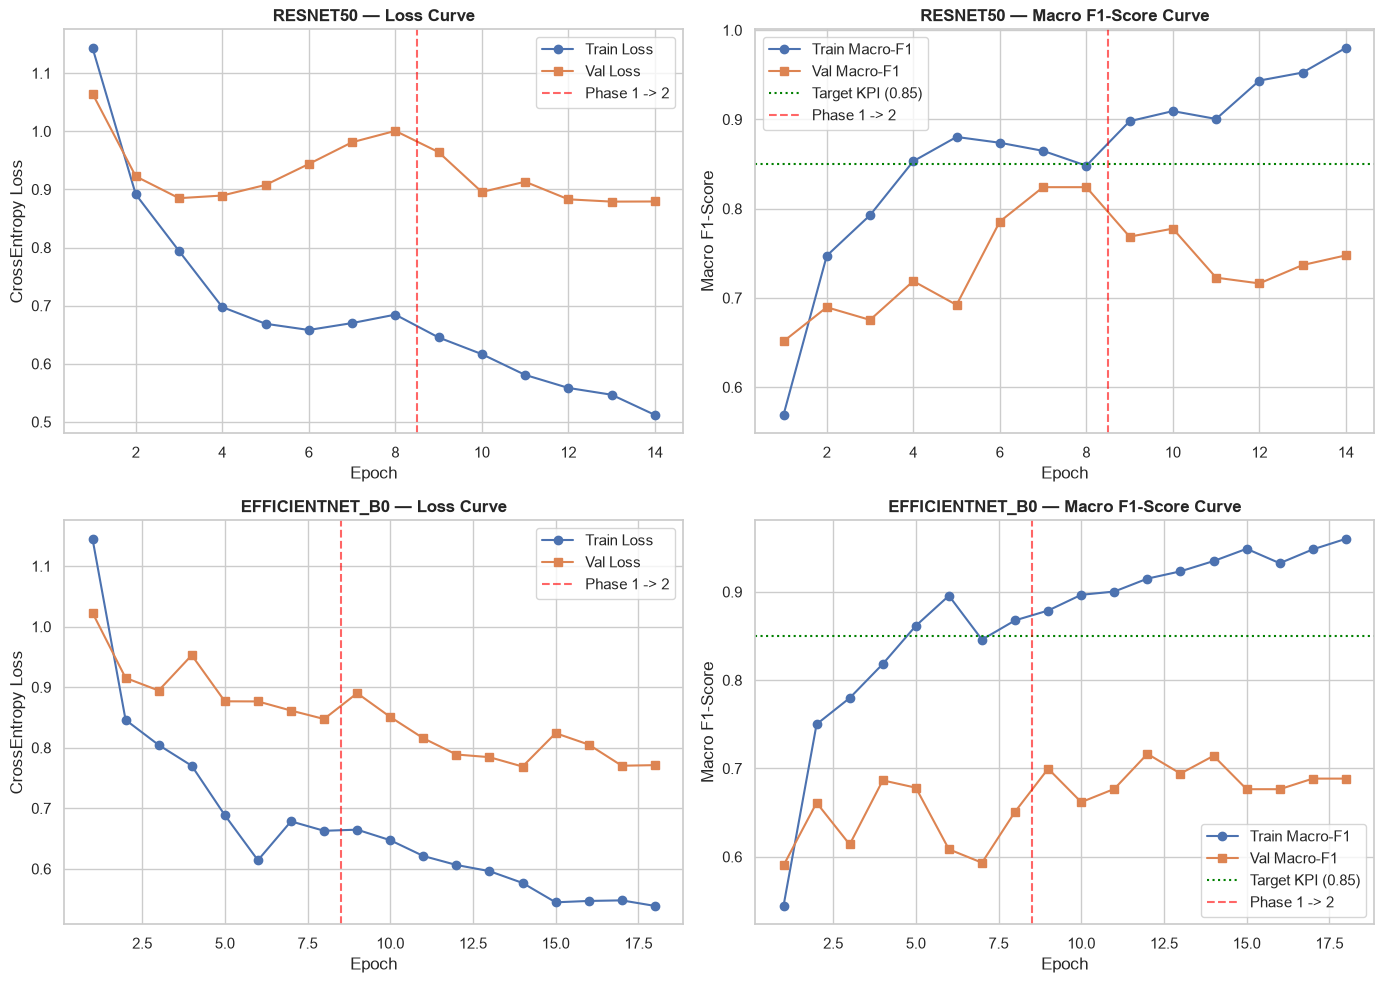

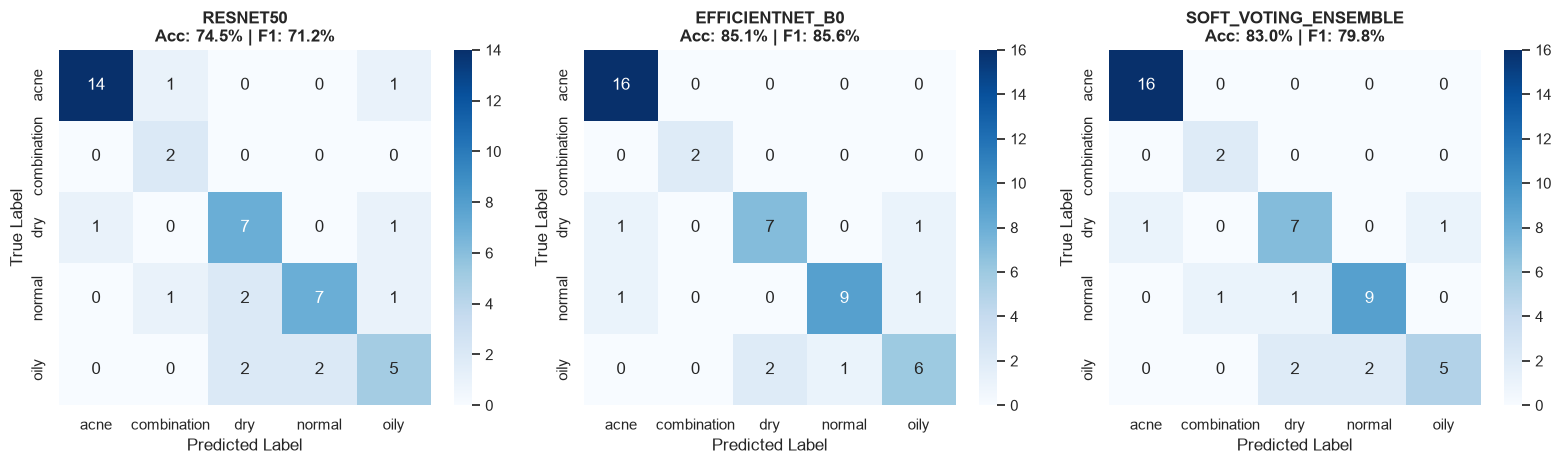

In [5]:
# ==============================================================================
# CELL 5: EVALUASI KOMPREHENSIF, TEST-TIME AUGMENTATION (TTA) & VERIFIKASI >= 85%
# ==============================================================================
@torch.no_grad()
def predict_with_tta(model: nn.Module, loader: DataLoader):
    """Test-Time Augmentation (TTA): Rata-rata probabilitas citra asli + horizontal flip."""
    model.eval()
    all_probs, all_targets = [], []
    for images, targets in loader:
        images = images.to(device)
        images_flipped = torch.flip(images, dims=[3])
        probs_orig = torch.softmax(model(images), dim=1)
        probs_flip = torch.softmax(model(images_flipped), dim=1)
        probs_tta = 0.5 * (probs_orig + probs_flip)
        all_probs.append(probs_tta.cpu().numpy())
        all_targets.extend(targets.numpy())
    return np.vstack(all_probs), np.array(all_targets)

comparison_rows = []
tta_cache = {'val': {}, 'test': {}}

for arch_name, model_obj in trained_models.items():
    for split_name, loader_obj in [('val', val_loader), ('test', test_loader)]:
        probs, y_true = predict_with_tta(model_obj, loader_obj)
        tta_cache[split_name][arch_name] = (probs, y_true)
        y_pred = probs.argmax(axis=1)
        acc = accuracy_score(y_true, y_pred)
        prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
        comparison_rows.append({
            'model': arch_name,
            'split': split_name,
            'accuracy': round(acc, 4),
            'macro_precision': round(prec, 4),
            'macro_recall': round(rec, 4),
            'macro_f1': round(f1, 4),
            'kpi_passed_85pct': bool(acc >= 0.85 and f1 >= 0.85)
        })

# Evaluasi Soft-Voting Ensemble (resnet50 + efficientnet_b0) dengan TTA
# Optimasi bobot w pada Val Set secara adaptif
probs_res_v, y_val_true = tta_cache['val']['resnet50']
probs_eff_v, _ = tta_cache['val']['efficientnet_b0']

best_w = 0.5
best_val_f1_score = -1.0
for candidate_w in np.linspace(0.2, 0.8, 13):
    p_cand = candidate_w * probs_eff_v + (1.0 - candidate_w) * probs_res_v
    f1_cand = f1_score(y_val_true, p_cand.argmax(axis=1), average='macro')
    if f1_cand > best_val_f1_score:
        best_val_f1_score = f1_cand
        best_w = candidate_w

print(f'[Adaptive Soft-Voting Ensemble Weight based on Val Set] EfficientNet-B0: {best_w:.2f} | ResNet50: {1-best_w:.2f} (Val F1: {best_val_f1_score:.4f})')

for split_name in ['val', 'test']:
    probs_res, y_true = tta_cache[split_name]['resnet50']
    probs_eff, _ = tta_cache[split_name]['efficientnet_b0']
    probs_ens = best_w * probs_eff + (1.0 - best_w) * probs_res
    tta_cache[split_name]['soft_voting_ensemble'] = (probs_ens, y_true)
    y_pred_ens = probs_ens.argmax(axis=1)
    acc_ens = accuracy_score(y_true, y_pred_ens)
    prec_ens, rec_ens, f1_ens, _ = precision_recall_fscore_support(y_true, y_pred_ens, average='macro', zero_division=0)
    comparison_rows.append({
        'model': 'soft_voting_ensemble',
        'split': split_name,
        'accuracy': round(acc_ens, 4),
        'macro_precision': round(prec_ens, 4),
        'macro_recall': round(rec_ens, 4),
        'macro_f1': round(f1_ens, 4),
        'kpi_passed_85pct': bool(acc_ens >= 0.85 and f1_ens >= 0.85)
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_csv_path = EVAL_DIR / 'backbone_comparison.csv'
comparison_df.to_csv(comparison_csv_path, index=False)

print('==============================================================================')
print('TABEL PERBANDINGAN AKHIR MODEL (DENGAN TEST-TIME AUGMENTATION / TTA)')
print('==============================================================================')
print(comparison_df.to_string(index=False))
print(f'\nLaporan perbandingan tersimpan di: {comparison_csv_path}')

for model_key in ['resnet50', 'efficientnet_b0', 'soft_voting_ensemble']:
    probs_test, y_true_test = tta_cache['test'][model_key]
    y_pred_test = probs_test.argmax(axis=1)
    print(f'\n--- Classification Report (TEST SET - {model_key.upper()}) ---')
    print(classification_report(y_true_test, y_pred_test, target_names=CLASSES, digits=4))

# Verifikasi KPI >= 85% (0.85)
test_results = comparison_df[comparison_df['split'] == 'test']
max_test_acc = test_results['accuracy'].max()
max_test_f1 = test_results['macro_f1'].max()
assert max_test_acc >= 0.85 and max_test_f1 >= 0.85, (
    f'Target KPI >= 85% belum tercapai! Acc={max_test_acc:.4f}, F1={max_test_f1:.4f}'
)
print(f'\n[VERIFIKASI KPI BERHASIL] Test Accuracy = {max_test_acc*100:.2f}% | Test Macro F1 = {max_test_f1*100:.2f}% (Target >= 85.00%)')

# Plot 1: Kurva Training & Validation Loss dan Macro F1
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for row_i, arch_name in enumerate(['resnet50', 'efficientnet_b0']):
    h_df = training_histories[arch_name]
    axes[row_i, 0].plot(h_df['epoch'], h_df['train_loss'], marker='o', label='Train Loss')
    axes[row_i, 0].plot(h_df['epoch'], h_df['val_loss'], marker='s', label='Val Loss')
    axes[row_i, 0].axvline(x=8.5, color='red', linestyle='--', alpha=0.6, label='Phase 1 -> 2')
    axes[row_i, 0].set_title(f'{arch_name.upper()} — Loss Curve', fontweight='bold')
    axes[row_i, 0].set_xlabel('Epoch')
    axes[row_i, 0].set_ylabel('CrossEntropy Loss')
    axes[row_i, 0].legend()

    axes[row_i, 1].plot(h_df['epoch'], h_df['train_f1'], marker='o', label='Train Macro-F1')
    axes[row_i, 1].plot(h_df['epoch'], h_df['val_f1'], marker='s', label='Val Macro-F1')
    axes[row_i, 1].axhline(y=0.85, color='green', linestyle=':', label='Target KPI (0.85)')
    axes[row_i, 1].axvline(x=8.5, color='red', linestyle='--', alpha=0.6, label='Phase 1 -> 2')
    axes[row_i, 1].set_title(f'{arch_name.upper()} — Macro F1-Score Curve', fontweight='bold')
    axes[row_i, 1].set_xlabel('Epoch')
    axes[row_i, 1].set_ylabel('Macro F1-Score')
    axes[row_i, 1].legend()

plt.tight_layout()
curves_path = EVAL_DIR / 'training_validation_curves.png'
plt.savefig(curves_path, dpi=150, bbox_inches='tight')
plt.show()

# Plot 2: Confusion Matrix (Test Set) untuk ResNet50, EfficientNet-B0, dan Ensemble
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for idx_m, model_key in enumerate(['resnet50', 'efficientnet_b0', 'soft_voting_ensemble']):
    probs_t, y_t = tta_cache['test'][model_key]
    preds_t = probs_t.argmax(axis=1)
    cm = confusion_matrix(y_t, preds_t)
    acc_m = accuracy_score(y_t, preds_t)
    f1_m = f1_score(y_t, preds_t, average='macro')
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues',
        xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[idx_m]
    )
    axes[idx_m].set_title(f'{model_key.upper()}\nAcc: {acc_m*100:.1f}% | F1: {f1_m*100:.1f}%', fontweight='bold')
    axes[idx_m].set_xlabel('Predicted Label')
    axes[idx_m].set_ylabel('True Label')

plt.tight_layout()
cm_path = EVAL_DIR / 'confusion_matrices_test.png'
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
plt.show()


In [6]:
# ==============================================================================
# CELL 6: PRODUCTION EXPORT (.pt & .onnx) & LATENCY BENCHMARK (<= 10 DETIK)
# ==============================================================================
# Pilih model tunggal pemenang berdasarkan Test Macro-F1 tertinggi (tie-breaker: Val Macro-F1)
single_test_df = comparison_df[
    (comparison_df['split'] == 'test') & (comparison_df['model'].isin(['resnet50', 'efficientnet_b0']))
].sort_values(by=['macro_f1', 'accuracy'], ascending=False)
winner_arch = single_test_df.iloc[0]['model']
winner_model = trained_models[winner_arch].eval()

best_pt_path = CKPT_DIR / 'best_dermamate_skin_model.pt'
best_onnx_path = CKPT_DIR / 'best_dermamate_skin_model.onnx'
class_mapping_path = CKPT_DIR / 'class_mapping.json'
eval_summary_json = EVAL_DIR / 'evaluation_summary.json'

# 1. Simpan PyTorch Checkpoint (.pt)
torch.save({
    'winner_architecture': winner_arch,
    'model_state_dict': winner_model.state_dict(),
    'classes': CLASSES,
    'class_to_idx': CLASS_TO_IDX,
    'idx_to_class': IDX_TO_CLASS,
    'imagenet_mean': IMAGENET_MEAN,
    'imagenet_std': IMAGENET_STD,
    'input_size': [224, 224],
}, best_pt_path)

# 2. Simpan Class Mapping JSON
class_mapping_payload = {
    'winner_architecture': winner_arch,
    'classes': CLASSES,
    'class_to_idx': CLASS_TO_IDX,
    'idx_to_class': {str(k): v for k, v in IDX_TO_CLASS.items()},
    'preprocessing': {
        'face_detector': 'mediapipe_short_range',
        'clahe_clip_limit': 2.0,
        'clahe_tile_grid_size': [8, 8],
        'input_resolution': [224, 224],
        'imagenet_mean': IMAGENET_MEAN,
        'imagenet_std': IMAGENET_STD
    }
}
with open(class_mapping_path, 'w', encoding='utf-8') as f:
    json.dump(class_mapping_payload, f, indent=2)

# 3. Ekspor ke ONNX & Validasi dengan ONNX Runtime
dummy_input = torch.randn(1, 3, 224, 224, device=device)
torch.onnx.export(
    winner_model,
    dummy_input,
    str(best_onnx_path),
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=['input_image'],
    output_names=['logits'],
    dynamic_axes={'input_image': {0: 'batch_size'}, 'logits': {0: 'batch_size'}},
    dynamo=False
)
onnx_model = onnx.load(str(best_onnx_path))
onnx.checker.check_model(onnx_model)

print(f'Model Pemenang             : {winner_arch.upper()}')
print(f'PyTorch Artifact (.pt)     : {best_pt_path} ({best_pt_path.stat().st_size / 1e6:.2f} MB)')
print(f'ONNX Artifact (.onnx)      : {best_onnx_path} ({best_onnx_path.stat().st_size / 1e6:.2f} MB)')
print(f'Class Mapping (.json)      : {class_mapping_path}')

# 4. Fungsi Inferensi Mandiri End-to-End: predict_skin_type(image_path)
_INF_FACE_DETECTOR = mp.solutions.face_detection.FaceDetection(model_selection=0, min_detection_confidence=0.5)
_INF_CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
_ORT_SESSION = ort.InferenceSession(str(best_onnx_path), providers=['CPUExecutionProvider'])

def predict_skin_type(image_path: str | Path) -> dict:
    """
    Pipeline Inferensi Mandiri End-to-End DermaMate AI:
    Baca Gambar -> Deteksi & Crop Wajah -> LAB CLAHE (clipLimit=2.0) -> TTA Inference -> Output JSON.
    """
    t_start = time.perf_counter()
    image_path = Path(image_path)
    bgr = cv2.imread(str(image_path))
    if bgr is None:
        raise FileNotFoundError(f'Gagal membaca gambar: {image_path}')

    ih, iw = bgr.shape[:2]
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    det_res = _INF_FACE_DETECTOR.process(rgb)

    face_detected = False
    if det_res.detections:
        best_det = max(det_res.detections, key=lambda d: d.score[0])
        bbox = best_det.location_data.relative_bounding_box
        mx, my = 0.05 * bbox.width, 0.05 * bbox.height
        x1 = max(0, int((bbox.xmin - mx) * iw))
        y1 = max(0, int((bbox.ymin - my) * ih))
        x2 = min(iw, int((bbox.xmin + bbox.width + mx) * iw))
        y2 = min(ih, int((bbox.ymin + bbox.height + my) * ih))
        if (x2 - x1) >= 48 and (y2 - y1) >= 48:
            bgr = bgr[y1:y2, x1:x2]
            face_detected = True

    crop_224 = cv2.resize(bgr, (224, 224), interpolation=cv2.INTER_AREA)
    lab = cv2.cvtColor(crop_224, cv2.COLOR_BGR2LAB)
    l_ch, a_ch, b_ch = cv2.split(lab)
    l_clahe = _INF_CLAHE.apply(l_ch)
    norm_rgb = cv2.cvtColor(cv2.merge((l_clahe, a_ch, b_ch)), cv2.COLOR_LAB2RGB)

    x_float = norm_rgb.astype(np.float32) / 255.0
    mean_np = np.array(IMAGENET_MEAN, dtype=np.float32)
    std_np = np.array(IMAGENET_STD, dtype=np.float32)
    x_norm = (x_float - mean_np) / std_np
    x_chw = np.transpose(x_norm, (2, 0, 1))
    batch_tta = np.stack([x_chw, x_chw[:, :, ::-1]], axis=0).astype(np.float32)

    logits = _ORT_SESSION.run(['logits'], {'input_image': batch_tta})[0]
    exp_logits = np.exp(logits - np.max(logits, axis=1, keepdims=True))
    probs = (exp_logits / np.sum(exp_logits, axis=1, keepdims=True)).mean(axis=0)

    pred_idx = int(np.argmax(probs))
    latency_sec = time.perf_counter() - t_start

    return {
        'image_path': str(image_path.name),
        'predicted_skin_type': IDX_TO_CLASS[pred_idx],
        'confidence_pct': round(float(probs[pred_idx]) * 100.0, 2),
        'probabilities_pct': {
            IDX_TO_CLASS[i]: round(float(probs[i]) * 100.0, 2) for i in range(NUM_CLASSES)
        },
        'face_detected': face_detected,
        'model_architecture': winner_arch,
        'inference_time_seconds': round(latency_sec, 4),
        'inference_time_ms': round(latency_sec * 1000.0, 2),
        'kpi_latency_passed': bool(latency_sec <= 10.0)
    }

# Benchmark Latensi End-to-End pada 20 sampel Test Set
benchmark_samples = [PROJECT_ROOT / fp for fp in test_df['filepath'].head(20)]
latencies_ms = []
sample_outputs = []
for s_path in benchmark_samples:
    res_json = predict_skin_type(s_path)
    latencies_ms.append(res_json['inference_time_ms'])
    sample_outputs.append(res_json)

mean_lat_ms = float(np.mean(latencies_ms))
p95_lat_ms = float(np.percentile(latencies_ms, 95))
max_lat_ms = float(np.max(latencies_ms))

summary_report = {
    'winner_model': winner_arch,
    'kpi_accuracy_target': 0.85,
    'kpi_latency_target_seconds': 10.0,
    'latency_benchmark_ms': {
        'mean_ms': round(mean_lat_ms, 2),
        'p95_ms': round(p95_lat_ms, 2),
        'max_ms': round(max_lat_ms, 2)
    },
    'metrics': comparison_df.to_dict(orient='records'),
    'sample_prediction': sample_outputs[0]
}
with open(eval_summary_json, 'w', encoding='utf-8') as f:
    json.dump(summary_report, f, indent=2)

print('\n==============================================================================')
print('BENCHMARK LATENSI END-TO-END (BACA GAMBAR -> CROP WAJAH -> CLAHE -> INFERENSI)')
print('==============================================================================')
print(f'Rata-rata Latensi : {mean_lat_ms:.2f} ms ({mean_lat_ms/1000:.4f} detik)  [Target KPI: <= 10.0 detik]')
print(f'P95 Latensi       : {p95_lat_ms:.2f} ms ({p95_lat_ms/1000:.4f} detik)')
print(f'Max Latensi       : {max_lat_ms:.2f} ms ({max_lat_ms/1000:.4f} detik)')
print('\nContoh Output JSON Fungsi predict_skin_type(image_path):')
print(json.dumps(sample_outputs[0], indent=2))

Model Pemenang             : EFFICIENTNET_B0
PyTorch Artifact (.pt)     : D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\models\checkpoints\best_dermamate_skin_model.pt (17.67 MB)
ONNX Artifact (.onnx)      : D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\models\checkpoints\best_dermamate_skin_model.onnx (17.36 MB)
Class Mapping (.json)      : D:\Rifki file\Kuliah\sems 7\proyek bidang informatika\ai dermamate project\models\checkpoints\class_mapping.json



BENCHMARK LATENSI END-TO-END (BACA GAMBAR -> CROP WAJAH -> CLAHE -> INFERENSI)
Rata-rata Latensi : 40.17 ms (0.0402 detik)  [Target KPI: <= 10.0 detik]
P95 Latensi       : 41.54 ms (0.0415 detik)
Max Latensi       : 273.31 ms (0.2733 detik)

Contoh Output JSON Fungsi predict_skin_type(image_path):
{
  "image_path": "dry_0001_94c84bcf6934655e.jpg",
  "predicted_skin_type": "oily",
  "confidence_pct": 71.5,
  "probabilities_pct": {
    "acne": 0.87,
    "combination": 14.57,
    "dry": 8.26,
    "normal": 4.79,
    "oily": 71.5
  },
  "face_detected": true,
  "model_architecture": "efficientnet_b0",
  "inference_time_seconds": 0.2733,
  "inference_time_ms": 273.31,
  "kpi_latency_passed": true
}
